# 응용 01 · BGR/RGB 변환과 채널 평균

`01_channels.py`의 A01 구현과 실제 출력 이미지를 확인합니다.

흐름: `data/scene.png` 읽기 → BGR에서 RGB로 변환 → 변환 전후 별도 Figure 저장 → BGR 채널 평균 CSV 저장.

`cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`는 RGB 순서의 새 배열을 반환합니다. Matplotlib의 `imshow`는 3채널 배열을 RGB로 해석합니다. BGR 배열을 그대로 전달하면 빨강과 파랑이 바뀌어 표시됩니다. `image.mean(axis=(0, 1))`은 높이·너비 축을 평균내므로 결과 순서는 원본의 B, G, R입니다.

이 노트북은 실제 코드를 실행하고 결과를 표시합니다. 입력은 보존하고 실습 코드의 출력 파일은 다시 생성합니다. 프로젝트 `.venv` 등 `opencv-python`, `numpy`, `matplotlib`, `pandas`, `IPython`이 설치된 커널에서 위에서부터 실행하세요.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image

# 노트북 폴더 또는 프로젝트 내부에서 실행할 수 있도록 루트를 찾습니다.
notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/02_응용/01_channels.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/02_응용"


## 1. 실습 코드 실행

현재 Python 파일의 코드를 사용합니다. 노트북에는 `__file__`이 없으므로 원본의 경로 준비 부분만 `exercise`로 바꿨습니다. TODO 구현과 출력 계산은 그대로입니다.

In [2]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
image = cv2.imread("data/scene.png")
# >>> TODO A01
# Matplotlib 표시 전에 BGR을 RGB로 변환하세요. 원본 image는 그대로 유지합니다.
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # cvtcolor로 변환 => COLOR_BGR2RGB로 미리 지정된 상수를 통해 rgb로 변환 (읽는순서 <원본>2<목표>)
# <<< TODO A01
# 각각 별도의 Figure입니다. 색공간 순서의 오류를 직접 비교합니다.
plt.figure(figsize=(5, 4)); plt.imshow(image); plt.title("Wrong: BGR interpreted as RGB"); plt.axis("off")
plt.tight_layout(); plt.savefig("outputs/p01_wrong.png", dpi=120); plt.close()
plt.figure(figsize=(5, 4)); plt.imshow(rgb); plt.title("Correct: RGB display"); plt.axis("off")
plt.tight_layout(); plt.savefig("outputs/p01_correct.png", dpi=120); plt.close()
means = image.mean(axis=(0, 1))
with open("outputs/p01_channels.csv", "w", encoding="utf-8-sig", newline="") as f:
    w = csv.writer(f); w.writerow(["channel", "mean"]); w.writerows(zip(["B", "G", "R"], means))
print("BGR 채널평균:", np.round(means, 3).tolist())
print("변환후 빨강:", rgb[30, 30].tolist())


BGR 채널평균: [111.002, 124.354, 118.358]
변환후 빨강: [255, 0, 0]


## 2. 실제 결과 확인과 검증

변환 전 BGR / 변환 후 RGB: [0, 0, 255] [255, 0, 0]
BGR 배열을 RGB로 해석한 그림


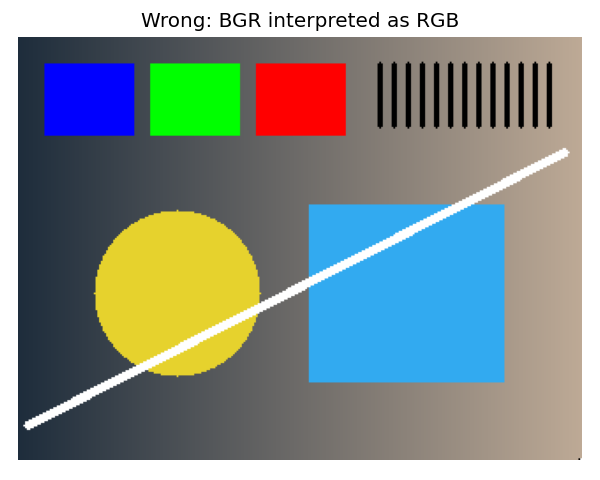

RGB 변환 후 표시한 그림


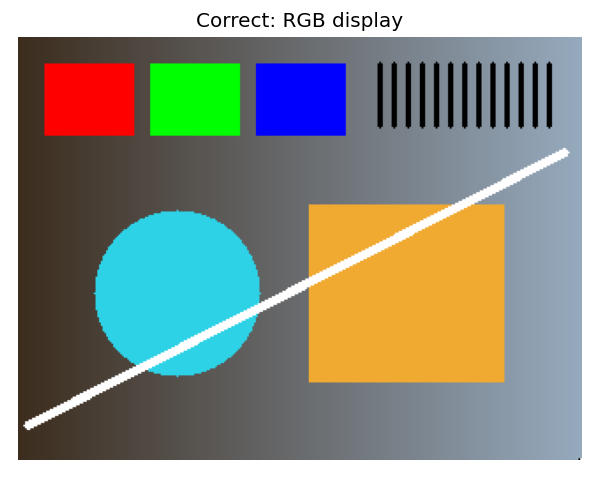

,channel,mean
0,B,111.001693
1,G,124.354180
2,R,118.358333


검증: 채널 순서 변환·원본 빨강 패치·채널 평균 일치


In [3]:
print("변환 전 BGR / 변환 후 RGB:", image[30, 30].tolist(), rgb[30, 30].tolist())
print("BGR 배열을 RGB로 해석한 그림")
display(Image(filename=str(exercise / "outputs/p01_wrong.png")))
print("RGB 변환 후 표시한 그림")
display(Image(filename=str(exercise / "outputs/p01_correct.png")))
channels = pd.read_csv("outputs/p01_channels.csv")
display(channels)
assert np.array_equal(rgb, image[:, :, ::-1])
assert image[30, 30].tolist() == [0, 0, 255]
assert rgb[30, 30].tolist() == [255, 0, 0]
assert channels["channel"].tolist() == ["B", "G", "R"]
assert np.allclose(channels["mean"], image.mean(axis=(0, 1)))
print("검증: 채널 순서 변환·원본 빨강 패치·채널 평균 일치")

## 3. 결과 해석

변환 전후 픽셀 값의 순서와 두 그림의 빨강·파랑 표시를 함께 확인합니다. CSV의 평균은 RGB로 변환한 배열이 아니라 원본 BGR 배열에서 계산한 값입니다.

출력 파일은 실행 중 생성되며, 이 노트북에는 실행 출력과 이미지가 포함되어 있습니다.

In [4]:
os.chdir(notebook_start)  # 노트북 실행 전 작업 폴더로 돌아갑니다.